# Real-time data assimilation with the CAE-ESN on the Kuramoto–Sivashinsky equation

The convolutional autoencoder echo state network (CAE-ESN) is a reduced-order model: a convolutional autoencoder (CAE) compresses each snapshot into a few reduced coordinates, and an echo state network (ESN) forecasts the reduced coordinates in time [1]. In this notebook, we assimilate sparse and noisy measurements into the CAE-ESN with an ensemble Kalman filter (EnKF), on the Kuramoto–Sivashinsky (KS) equation, which is the prototypical case of [2]. The schematic shows the method (here on the Kolmogorov flow of tutorial 46): the encoder initializes the ensemble, the ESN forecasts each member, the EnKF updates the reservoir states with the measurements, and the decoder maps the forecast back to the physical field.

<a><img src="../../docs/figs/DA/CAE-ESN_DA.png" width=900px></a>

The autoencoder comes from the repository of [2], [github.com/MagriLab/DA-CAE-ESN](https://github.com/MagriLab/DA-CAE-ESN); romda reimplements the network as `CAE1D`, with the same layer names, so the weights of [2] load unchanged (`CAE1D.load_state_dicts`).

[1] A. Racca, N. A. K. Doan & L. Magri (2023). Predicting turbulent dynamics with the convolutional autoencoder echo state network. *J. Fluid Mech.* 975, A2.

[2] E. Özalp, A. Nóvoa & L. Magri (2026). Real-time forecasting of chaotic dynamics from sparse data and autoencoders. *Comput. Methods Appl. Mech. Eng.* 450, 118600.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from romda.plotting import Palette

## 1. The Kuramoto–Sivashinsky equation

The KS equation,

$$
\frac{\partial u}{\partial t} + u\frac{\partial u}{\partial x} + \frac{\partial^2 u}{\partial x^2} + \frac{\partial^4 u}{\partial x^4} = 0,
$$

is a model of flame fronts and thin films, which is chaotic on long periodic domains. As in [2], the domain has length $L = 20\pi$ and 128 grid points, and the snapshots are $\Delta t = 0.25$ apart. The leading Lyapunov exponent is $\lambda_1 \approx 0.08$, so one Lyapunov time, $1/\lambda_1$, spans 50 snapshots. We integrate the equation with the `KS` model of dynamodels (ETDRK4 in Fourier space), discard the transient (`N_trans`), and split the record into training, validation and test snapshots.

training and validation, test snapshots: (41000, 128) (3000, 128)


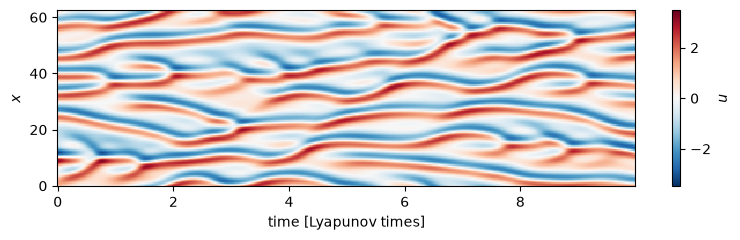

In [2]:
from dynamodels.physical import KS

N_trans, N_train, N_val, N_test = 1000, 40000, 1000, 3000
dt, t_lyap = 0.25, 12.5
ks = KS(Nx=128, L=20 * np.pi, dt=dt, seed=0)
psi, _ = ks.time_integrate(Nt=N_trans + N_train + N_val + N_test)
U = np.fft.irfft(psi[N_trans:, :, 0], axis=1)            # the state is in Fourier space
U_train, U_test = U[:N_train + N_val], U[N_train + N_val:]
x = np.linspace(0, 20 * np.pi, 128, endpoint=False)
u_max = np.abs(U_train).max()
print('training and validation, test snapshots:', U_train.shape, U_test.shape)

def hovmoller(ax, field, t, **kw):
    """Space-time diagram of a field (N_t, 128) against time in Lyapunov times."""
    return ax.pcolormesh(t, x, field.T, cmap=kw.pop('cmap', 'RdBu_r'), shading='auto', rasterized=True, **kw)

fig, ax = plt.subplots(figsize=(8, 2.5))
im = hovmoller(ax, U_test[:500], np.arange(500) * dt / t_lyap, vmin=-u_max, vmax=u_max)
ax.set(xlabel='time [Lyapunov times]', ylabel='$x$')
fig.colorbar(im, ax=ax, label='$u$')
fig.tight_layout()

## 2. The autoencoder

`CAE1D` is the autoencoder of [2]: periodic convolutions reduce the 128 grid points to 24 reduced coordinates, and every layer ends with a hyperbolic tangent, so the field is divided by its maximum absolute value. We load the weights of [2], which come with their normalization (`scale`, the maximum of $|u|$ in the record of [2]). These weights are trained on a different trajectory of the same equation, so the record of this notebook is new data for the autoencoder. We compare its reconstruction of the test set with the proper orthogonal decomposition (POD) truncated to the same number of modes.

24 reduced coordinates, 11687 parameters


1 - Energy on the test set: CAE 3.4e-02, POD 5.4e-02


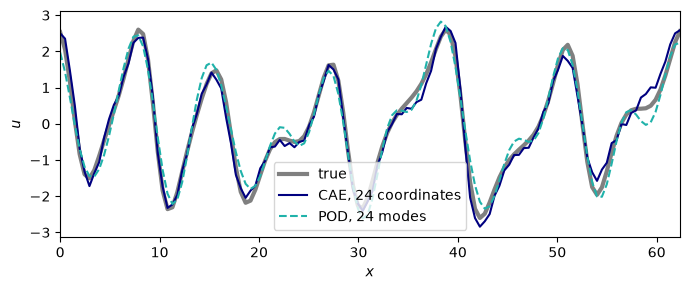

In [3]:
from romda.models.data_driven import CAE1D

state = torch.load('../weights/DA-CAE-ESN_ks_l20pi.pth', map_location='cpu')
cae = CAE1D.load_state_dicts(state, grid_shape=(1, 128, 1), scale=3.58)
print(f'{cae.N_latent} reduced coordinates, {cae.n_params} parameters')

def energy_error(U, U_hat):
    """1 - Energy: the squared reconstruction error relative to the energy of the field."""
    return np.sum((U - U_hat) ** 2) / np.sum(U ** 2)

X_test = U_test[None, :, :, None]                         # grid layout (Nu, N_t, Nx, Ny)
U_cae = cae.reconstruct(X_test).T
V = np.linalg.svd(U_train[::5], full_matrices=False)[2][:cae.N_latent]
U_pod = U_test @ V.T @ V
print(f'1 - Energy on the test set: CAE {energy_error(U_test, U_cae):.1e}, POD {energy_error(U_test, U_pod):.1e}')

k = 100
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x, U_test[k], color=Palette.TRUE, lw=3, label='true')
ax.plot(x, U_cae[k], color=Palette.UNBIASED, label=f'CAE, {cae.N_latent} coordinates')
ax.plot(x, U_pod[k], '--', color=Palette.BIASED, label=f'POD, {cae.N_latent} modes')
ax.set(xlabel='$x$', ylabel='$u$', xlim=x[[0, -1]])
ax.legend()
fig.tight_layout()

The figure compares a test snapshot with its two reconstructions; the printed 1 - Energy gives the comparison over the whole test set. The reconstruction error of the CAE is the lower bound of the error of any CAE-ESN forecast.

## 3. The CAE-ESN

`CAE1D_ESN` combines the autoencoder with `ESN_model` through `LatentROM`. We pass the trained autoencoder with `projector=`, so the training data only train the ESN, on the reduced coordinates of the training snapshots. The ESN has the hyperparameters that [2] selected (`rho`, `sigma_in`, `tikh`, a dense input matrix `Win_type='dense'`, and inputs normalized by their standard deviation), with fewer units (`N_units`) than [2] to keep the notebook light. The sensors, at which the model reads the decoded field, are 25 equispaced grid points.

In [4]:
from romda.models.data_driven import CAE1D_ESN

n_sensors = 25
sensors = np.linspace(0, 127, n_sensors).round().astype(int)
rom = CAE1D_ESN(data=U_train[None, :, :, None], dt=dt, projector=cae, sensor_locations=sensors,
                N_units=5000, N_wash=100, t_train=N_train * dt, t_val=N_val * dt, t_test=0., upsample=1,
                rho=0.272, sigma_in=0.147, tikh=1e-5, hyperparameters_to_optimize=[], Win_type='dense',
                norm_method='std', bias_in=np.array([1.]), connect=10, noise=1e-3,
                plot_training=False, seed=0)
print(f'state of the model: {rom.N_latent} reduced coordinates + {rom.N_units} reservoir states; {rom.Nq} observables')

state of the model: 24 reduced coordinates + 5000 reservoir states; 25 observables


Without data assimilation, the CAE-ESN is initialized on 100 encoded snapshots (the washout) and then forecasts in closed loop: each output is the next input. We measure the error of the decoded field, normalized by the root-mean-square of the true field, from several initial times in the test set. A normalized error of order one means that the forecast has lost the true state.

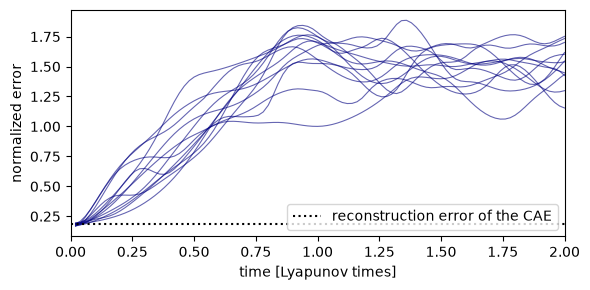

In [5]:
Z_test = cae.encode(X_test).T                              # (N_t, N_latent)
rms = np.sqrt(np.mean(np.sum(U_test ** 2, axis=1)))
n_forecast = 100
t_f = np.arange(1, n_forecast + 1) * dt / t_lyap

fig, ax = plt.subplots(figsize=(6, 3))
for i0 in range(0, N_test - n_forecast - 100, 250):
    Z_f, _ = rom.closed_loop(Z_test[i0:i0 + 100 + n_forecast], n_forecast)
    err = np.linalg.norm(rom.decode(Z_f.T).T - U_test[i0 + 100:i0 + 100 + n_forecast], axis=1) / rms
    ax.plot(t_f, err, color=Palette.UNBIASED, lw=0.8, alpha=0.6)
ax.axhline(np.sqrt(energy_error(U_test, U_cae)), color='k', ls=':', label='reconstruction error of the CAE')
ax.set(xlabel='time [Lyapunov times]', ylabel='normalized error', xlim=[0, t_f[-1]])
ax.legend()
fig.tight_layout()

Each line is a closed-loop forecast from a different initial time. The error starts at the reconstruction error of the CAE and reaches order one within a fraction of a Lyapunov time: the CAE-ESN forecasts the KS equation for a short time only, as reported in [2]. Data assimilation is what keeps it on the true state.

## 4. Data assimilation

We now forecast without knowing the initial state. The ensemble of 100 CAE-ESNs starts from reservoir states visited during training, so the members are unrelated to the true state. Every Lyapunov time ($\Delta t_\mathrm{obs} = 50\,\Delta t$, `n_obs`), the 25 sensors measure the field with a noise of standard deviation 10 % of the maximum of $|u|$ at each sensor, as in [2], and the EnKF updates the augmented state of each member, i.e. its reduced coordinates and its reservoir. We assimilate during ten Lyapunov times and then forecast for two more.

The observation operator is nonlinear, because the decoder maps the reduced coordinates to the field at the sensors; the EnKF does not need its Jacobian, because it estimates the covariance between the state and the observables from the ensemble.

In [6]:
from romda.observations import Observations
from romda.estimators import EnKF
from romda.data_assimilation import run_da_loop

sigma = 0.1 * np.abs(U_train).max(axis=0)[sensors]
rng = np.random.default_rng(1)
n_obs = 50
truth = Observations(y_raw=U_test[:, sensors] + sigma * rng.standard_normal((N_test, n_sensors)),
                     y_true=U_test[:, sensors], t_true=np.arange(N_test) * dt,
                     t_start=n_obs * dt, t_stop=10 * t_lyap, Nt_obs=n_obs)

ensemble = EnKF(parent_model=rom, m=100)
filt = run_da_loop(ensemble, truth, Cdd=np.diag(sigma ** 2), t_extra=2 * t_lyap)

normalized error of the ensemble mean: initial 1.05; mean at the analyses after 2 Lyapunov times 0.42; mean over the window after 2 Lyapunov times 0.79


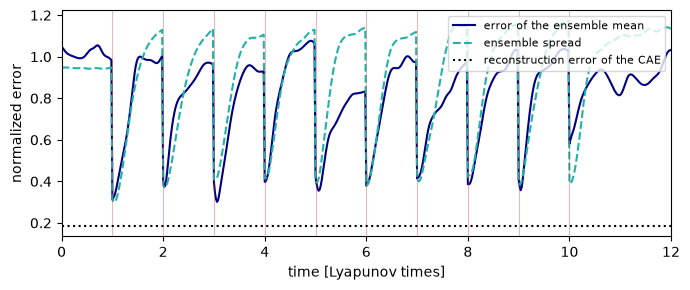

In [7]:
model = filt.model
t = np.asarray(model.hist_t)
keep = np.r_[t[1:] != t[:-1], True]                         # at the observation times, keep the analysis
t, Z = t[keep], model.hist[keep, :rom.N_latent]             # (N_t, N_latent, m)
idx = np.rint(t / dt).astype(int)
U_members = np.stack([rom.decode(Z[:, :, j].T).T for j in range(filt.m)])    # (m, N_t, 128)
U_mean = U_members.mean(0)                                  # mean of the decoded members
err_da = np.linalg.norm(U_mean - U_test[idx], axis=1) / rms
spread = np.sqrt(U_members.var(0).sum(-1)) / rms

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t / t_lyap, err_da, color=Palette.UNBIASED, label='error of the ensemble mean')
ax.plot(t / t_lyap, spread, '--', color=Palette.BIASED, label='ensemble spread')
for t_obs in truth.t_obs:
    ax.axvline(t_obs / t_lyap, color=Palette.OBS, lw=0.5, alpha=0.5)
ax.axhline(np.sqrt(energy_error(U_test, U_cae)), color='k', ls=':', label='reconstruction error of the CAE')
ax.set(xlabel='time [Lyapunov times]', ylabel='normalized error', xlim=[0, t[-1] / t_lyap])
ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
i_a = np.isin(idx, np.rint(truth.t_obs / dt).astype(int)) & (t > 2 * t_lyap)
print(f'normalized error of the ensemble mean: initial {err_da[0]:.2f}; mean at the analyses after 2 Lyapunov times '
      f'{err_da[i_a].mean():.2f}; mean over the window after 2 Lyapunov times {err_da[(t > 2 * t_lyap) & (t <= truth.t_obs[-1])].mean():.2f}')

The vertical lines mark the analyses. At each analysis, the EnKF moves the ensemble towards the true state and the error drops, although not to the reconstruction error of the CAE. Between analyses the error grows again, because the CAE-ESN loses the true state within a fraction of a Lyapunov time (section 3). The spread of the ensemble rises and falls with the error, so the ensemble gives an estimate of its own uncertainty, and the ensemble does not collapse. After the last measurement, the forecast loses the true state, as the forecasts of section 3 do.

The space-time diagrams compare the true field, the decoded ensemble mean and its absolute error. The measurements, at the sensors and at the analysis times, are marked on the true field.

Text(0.5, 0, 'time [Lyapunov times]')

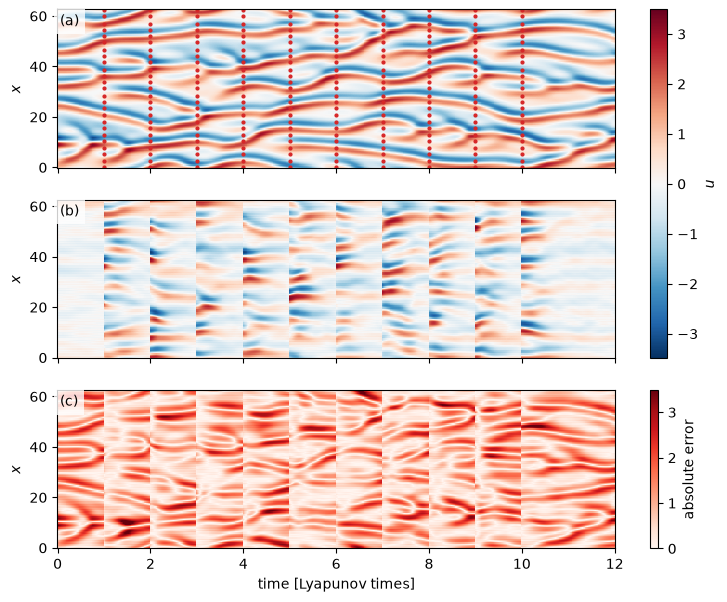

In [8]:
fig, axs = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
tl = t / t_lyap
hovmoller(axs[0], U_test[idx], tl, vmin=-u_max, vmax=u_max)
T_obs, X_obs = np.meshgrid(truth.t_obs / t_lyap, x[sensors], indexing='ij')
axs[0].scatter(T_obs, X_obs, s=4, color=Palette.OBS)
im = hovmoller(axs[1], U_mean, tl, vmin=-u_max, vmax=u_max)
fig.colorbar(im, ax=axs[:2], label='$u$')
im = hovmoller(axs[2], np.abs(U_mean - U_test[idx]), tl, cmap='Reds', vmin=0, vmax=u_max)
fig.colorbar(im, ax=axs[2], label='absolute error')
for ax, label in zip(axs, ['(a)', '(b)', '(c)']):
    ax.set_ylabel('$x$')
    ax.text(0.005, 0.97, label, transform=ax.transAxes, va='top', ha='left',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
axs[-1].set_xlabel('time [Lyapunov times]')

Panel (a) is the true field with the measurements (dots), (b) the decoded ensemble mean, and (c) its absolute error. Right after each analysis, the ensemble mean has the cells of the true field at the right positions. Within each interval the cells fade, because the members lose the true state and their mean averages them out; the error grows accordingly.

The short predictability time of the CAE-ESN on this case bounds the accuracy between analyses. To explore the method, change the time between analyses (`n_obs`), the number of sensors (`n_sensors`) or the size of the ensemble (`m`), and compare the error and the spread with the figures above. Tutorial 46 applies the same method to the two-dimensional Kolmogorov flow, on which the CAE-ESN forecasts for longer.